# ЗС 6. Вероятностный прогноз сроков MVP «Практики» (Монте-Карло)

**Вопрос заказчика:** когда будет готов MVP — всё, без чего методист может отказаться от Excel (13 историй релизов «ходячий скелет» и «MVP» из ЛЗ 4)?

**Метод:** берём реальную историю throughput (сколько задач команда закрывает за неделю), 10 000 раз «проигрываем» будущее, случайно вытягивая недели из истории, и смотрим распределение дат завершения. Ответ — диапазон с вероятностями, а не одна дата.

**Воспроизводимость:** данные лежат в репозитории (`analytics/data/`), генератор случайных чисел зафиксирован (`SEED`). Тот же результат в Jupyter, VS Code и Google Colab. Для Colab загрузите папку `analytics/` и `docs/` из репозитория или клонируйте его.

In [1]:
import csv
from datetime import date, timedelta
from pathlib import Path

import matplotlib
import matplotlib.dates
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import yaml

ROOT = Path.cwd() if (Path.cwd() / "analytics").exists() else Path.cwd().parent
DATA = ROOT / "analytics" / "data" / "closed_issues_jazzband__pip-tools.csv"
STORIES = ROOT / "docs" / "requirements" / "stories.yaml"
TEAM = ROOT / "docs" / "planning" / "team.yaml"

SEED = 2026
RUNS = 10_000
START = date(2026, 10, 12)          # понедельник недели 6: начало прогноза
HISTORY_FROM = date(2025, 10, 6)    # 52 недели истории
DEADLINES = {"M3 · защита 18.12.2026": date(2026, 12, 18), "M4 · запуск 01.02.2027": date(2027, 2, 1)}

plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#898781", "#0b0b0b"


## 1. Исторический throughput

**Откуда данные.** Своей истории у команды ещё нет: спринты начнутся в ЗС 9. Задание разрешает взять открытый репозиторий, поэтому мы взяли **jazzband/pip-tools**. Почему он, а не крупный проект вроде FastAPI: задачи там закрывает небольшая команда волонтёров, которые работают над проектом в свободное время. Так же и у нас: два студента с другими предметами. За год они закрыли 48 задач — около одной в неделю. У крупного проекта с оплачиваемой командой было бы 20–50 в неделю, и прогноз был бы бессмысленно оптимистичным.

Считаем только issues, закрытые как выполненные (без pull request, дублей и «не будем делать»). Снимок выгружен скриптом `analytics/fetch_throughput.py`.

Задач за 52 недели: 48, в среднем 0.92 в неделю
Недель без единой закрытой задачи: 62%, максимум за неделю: 9


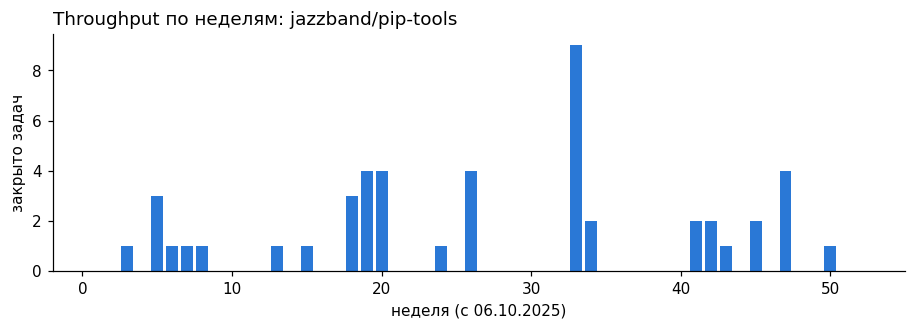

In [2]:
rows = list(csv.DictReader(open(DATA, encoding="utf-8")))
weeks = np.zeros(52, dtype=int)
for r in rows:
    w = (date.fromisoformat(r["closed"]) - HISTORY_FROM).days // 7
    if 0 <= w < 52:
        weeks[w] += 1

print(f"Задач за 52 недели: {weeks.sum()}, в среднем {weeks.mean():.2f} в неделю")
print(f"Недель без единой закрытой задачи: {(weeks == 0).mean():.0%}, максимум за неделю: {weeks.max()}")

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(range(1, 53), weeks, color=BLUE, width=0.8)
ax.set_xlabel("неделя (с 06.10.2025)")
ax.set_ylabel("закрыто задач")
ax.set_title("Throughput по неделям: jazzband/pip-tools", loc="left")
plt.show()

Throughput очень неровный: в 6 неделях из 10 не закрыто ни одной задачи, потом бывают всплески по 4–9. Как раз поэтому среднее «≈ 1 задача в неделю» опасно для планирования: оно скрывает длинные паузы.

## 2. Бэклог и календарь команды

Размер бэклога берём из `stories.yaml` (ЛЗ 4). Календарь — из ЛЗ 5: в неделю рубежного контроля команда работает примерно вполовину, во время сессии (21.12–17.01) — ноль, на каникулах — 80 %. Сколько задач «доживает» до конца недели, моделируем биномиально: каждая вытянутая из истории задача закрывается с вероятностью, равной доле рабочей недели.

In [3]:
backlog = yaml.safe_load(open(STORIES, encoding="utf-8"))["stories"]
team = yaml.safe_load(open(TEAM, encoding="utf-8"))
N_MVP = sum(1 for s in backlog if s["release"] in ("skeleton", "mvp"))
SP_MVP = sum(s["points"] for s in backlog if s["release"] in ("skeleton", "mvp"))
N_ALL = len(backlog)
WEEK1 = date(2026, 9, 7)
FACTORS = {int(k): v for k, v in team["capacity"]["week_factors"].items()}


def week_factor(monday: date) -> float:
    k = (monday - WEEK1).days // 7 + 1
    if 6 <= k <= 15:
        return FACTORS.get(k, 1.0)
    if date(2026, 12, 21) <= monday < date(2027, 1, 18):   # сессия
        return 0.0
    if date(2027, 1, 18) <= monday < date(2027, 2, 1):     # каникулы
        return 0.8
    return 1.0


print(f"MVP: {N_MVP} историй, {SP_MVP} SP; весь бэклог: {N_ALL} историй")

MVP: 13 историй, 51 SP; весь бэклог: 20 историй


## 3. Симуляция: 10 000 прогонов

In [4]:
def simulate(n_items: int, runs: int = RUNS, seed: int = SEED) -> np.ndarray:
    rng = np.random.default_rng(seed)
    finish = np.empty(runs, dtype="datetime64[D]")
    for i in range(runs):
        done, w = 0, 0
        while done < n_items:
            monday = START + timedelta(weeks=w)
            done += rng.binomial(rng.choice(weeks), week_factor(monday))
            w += 1
        finish[i] = np.datetime64(START + timedelta(weeks=w) - timedelta(days=1))  # конец последней недели
    return finish


def percentiles(finish: np.ndarray) -> dict:
    s = np.sort(finish)
    return {p: s[int(p / 100 * len(s)) - 1].astype(date) for p in (50, 70, 85, 95)}


fmt = lambda d: d.strftime("%d.%m.%Y")  # noqa: E731
results = {}
for label, n in [(f"MVP ({N_MVP} историй)", N_MVP), (f"MVP после CR-001 ({N_MVP - 1})", N_MVP - 1),
                 (f"весь бэклог ({N_ALL})", N_ALL)]:
    f = simulate(n)
    results[label] = f
    ps = percentiles(f)
    print(label)
    for p, d in ps.items():
        print(f"   P{p}: {fmt(d)}")
    for name, dl in DEADLINES.items():
        print(f"   вероятность успеть к {name}: {(f <= np.datetime64(dl)).mean():.0%}")

MVP (13 историй)
   P50: 07.03.2027
   P70: 28.03.2027
   P85: 02.05.2027
   P95: 06.06.2027
   вероятность успеть к M3 · защита 18.12.2026: 14%
   вероятность успеть к M4 · запуск 01.02.2027: 24%


MVP после CR-001 (12)
   P50: 28.02.2027
   P70: 21.03.2027
   P85: 18.04.2027
   P95: 23.05.2027
   вероятность успеть к M3 · защита 18.12.2026: 18%
   вероятность успеть к M4 · запуск 01.02.2027: 29%


весь бэклог (20)
   P50: 02.05.2027
   P70: 30.05.2027
   P85: 04.07.2027
   P95: 15.08.2027
   вероятность успеть к M3 · защита 18.12.2026: 2%
   вероятность успеть к M4 · запуск 01.02.2027: 4%


## 4. Гистограмма и кумулятивная кривая для MVP

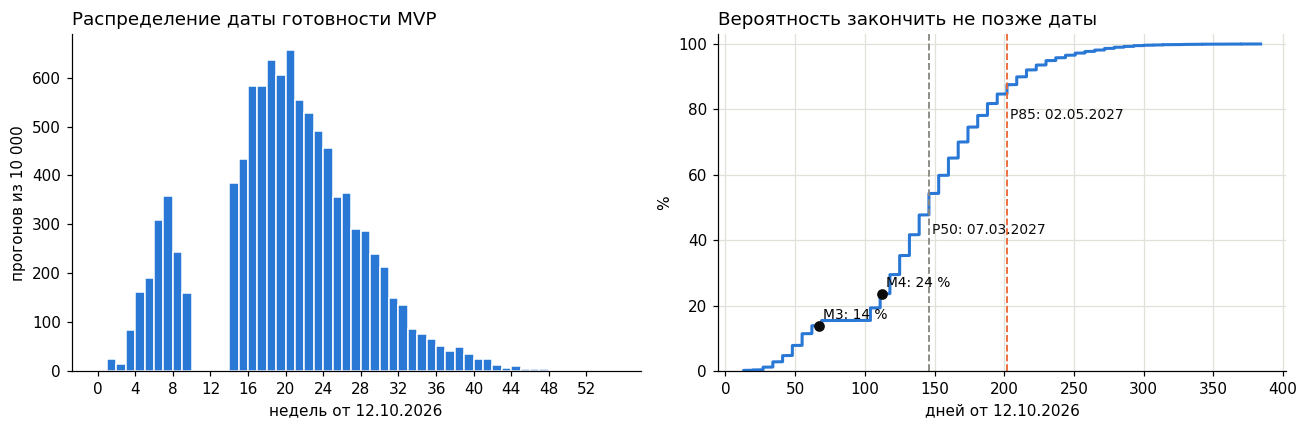

In [5]:
mvp = results[f"MVP ({N_MVP} историй)"]
ps = percentiles(mvp)
days = (mvp - np.datetime64(START)).astype(int)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
bins = np.arange(0, days.max() + 8, 7)
a1.hist(days, bins=bins, color=BLUE, edgecolor="white")
a1.set_title("Распределение даты готовности MVP", loc="left")
a1.set_xlabel("недель от 12.10.2026")
a1.set_xticks(bins[::4], [str(int(b // 7)) for b in bins[::4]])
a1.set_ylabel("прогонов из 10 000")

xs = np.sort(days)
a2.plot(xs, np.arange(1, len(xs) + 1) / len(xs) * 100, color=BLUE, lw=2)
for p, c in [(50, GREY), (85, ORANGE)]:
    d = (np.datetime64(ps[p]) - np.datetime64(START)).astype(int)
    a2.axvline(d, color=c, ls="--", lw=1.2)
    a2.text(d + 2, p - 8, f"P{p}: {fmt(ps[p])}", color=INK, fontsize=9)
for name, dl in DEADLINES.items():
    d = (np.datetime64(dl) - np.datetime64(START)).astype(int)
    prob = (mvp <= np.datetime64(dl)).mean() * 100
    a2.plot([d], [prob], "o", color=INK)
    a2.text(d + 3, prob + 2, f"{name.split(' · ')[0]}: {prob:.0f} %", fontsize=9)
a2.set_title("Вероятность закончить не позже даты", loc="left")
a2.set_xlabel("дней от 12.10.2026")
a2.set_ylabel("%")
a2.set_ylim(0, 103)
a2.grid(color="#e1e0d9")
plt.tight_layout()
plt.show()

## 5. Сравнение с детерминированной оценкой по story points

План релизов ЛЗ 5 обещает весь MVP к вехе M3 (18.12.2026). Неявно это значит скорость около 51 SP за 10 рабочих недель, то есть ~5 SP в неделю, без пауз и без сюрпризов.

In [6]:
plan_weeks = SP_MVP / 5
det = START + timedelta(weeks=plan_weeks)
p_det = (mvp <= np.datetime64(det)).mean()
print(f"Детерминированно: {SP_MVP} SP / 5 SP в неделю = {plan_weeks:.1f} недели → {fmt(det)}")
print(f"По Монте-Карло вероятность успеть к этой дате: {p_det:.0%}")
print(f"P50 = {fmt(ps[50])}, P85 = {fmt(ps[85])}")

Детерминированно: 51 SP / 5 SP в неделю = 10.2 недели → 22.12.2026
По Монте-Карло вероятность успеть к этой дате: 15%
P50 = 07.03.2027, P85 = 02.05.2027


**Почему такой разрыв:**

1. **Среднее против распределения.** Детерминированная оценка — это одна точка, «если всё пойдёт как в среднем». Но в 6 неделях из 10 история показывает ноль закрытых задач. Средняя скорость не говорит, сколько будет пустых недель подряд.
2. **Story points — не время.** SP измеряют относительный размер, а не часы. Перевод «5 SP в неделю» взят с потолка: собственной скорости у команды ещё нет.
3. **Календарь.** В плане недели одинаковые, а в реальности есть рубежные контроли, праздник 26.10, сессия на четыре недели. Симуляция учитывает их, детерминированный план — нет.
4. **Ожидание других.** Throughput из истории уже включает ожидание ревью, ответов и внешних решений. План ЛЗ 5 предполагает, что все 12 зависимостей будут подтверждены вовремя.
5. **Тот же вывод, что в ЛЗ 5.** Capacity команды покрывает около 52 % работы. Монте-Карло пришёл к той же картине с другой стороны: медиана — март, а не декабрь.

**Ограничение прогноза.** Throughput взят у другой команды. Это честная стартовая точка, но не наша скорость. После двух спринтов (ЗС 9) меняем `DATA` на выгрузку из нашего репозитория и пересчитываем.

## 6. Покер планирования: 10 историй

Протокол заполняется командой в `analytics/planning_poker.csv`: каждый выбирает карту (1, 2, 3, 5, 8, 13) молча, вскрываем одновременно. Если разброс больше одной карты, автор самой высокой и самой низкой оценки объясняет причину, затем второй раунд. Ячейка ниже считает разброс, как только в таблице появятся оценки.

In [7]:
poker = list(csv.DictReader(open(ROOT / "analytics" / "planning_poker.csv", encoding="utf-8")))
print("Оценка из ЛЗ 4 и независимая оценка AI (колонка ai_sp, подписана как оценка Claude):")
for r in poker:
    lz4, ai = int(r["sp_lz4"]), int(r["ai_sp"])
    mark = "" if lz4 == ai else "  ← обсудить"
    print(f"  {r['story']}: ЛЗ 4 = {lz4}, AI = {ai}{mark}")
diff = [r["story"] for r in poker if r["sp_lz4"] != r["ai_sp"]]
print(f"Расходятся {len(diff)} из {len(poker)}: {', '.join(diff)}")

filled = [r for r in poker if r["round1_pm"] and r["round1_ba"]]
if not filled:
    print(f"\nГолосов команды пока нет: {len(poker)} историй ждут покера планирования.")
else:
    print("\nПервый раунд команды:")
    spread = []
    for r in filled:
        a, b, ai = int(r["round1_pm"]), int(r["round1_ba"]), int(r["ai_sp"])
        spread.append(max(a, b) / min(a, b))
        print(f"  {r['story']}: Әлібек {a} / Нұркен {b} / AI {ai}, разброс {spread[-1]:.1f}×")
    print(f"Средний разброс первого раунда: {np.mean(spread):.2f}×")

Оценка из ЛЗ 4 и независимая оценка AI (колонка ai_sp, подписана как оценка Claude):
  S01: ЛЗ 4 = 3, AI = 3
  S02: ЛЗ 4 = 3, AI = 2  ← обсудить
  S04: ЛЗ 4 = 5, AI = 3  ← обсудить
  S05: ЛЗ 4 = 3, AI = 2  ← обсудить
  S07: ЛЗ 4 = 3, AI = 3
  S08: ЛЗ 4 = 5, AI = 5
  S10: ЛЗ 4 = 5, AI = 5
  S14: ЛЗ 4 = 5, AI = 8  ← обсудить
  S15: ЛЗ 4 = 2, AI = 2
  S16: ЛЗ 4 = 8, AI = 8
Расходятся 4 из 10: S02, S04, S05, S14

Голосов команды пока нет: 10 историй ждут покера планирования.


## 7. Слайд «Когда будет готово» для заказчика

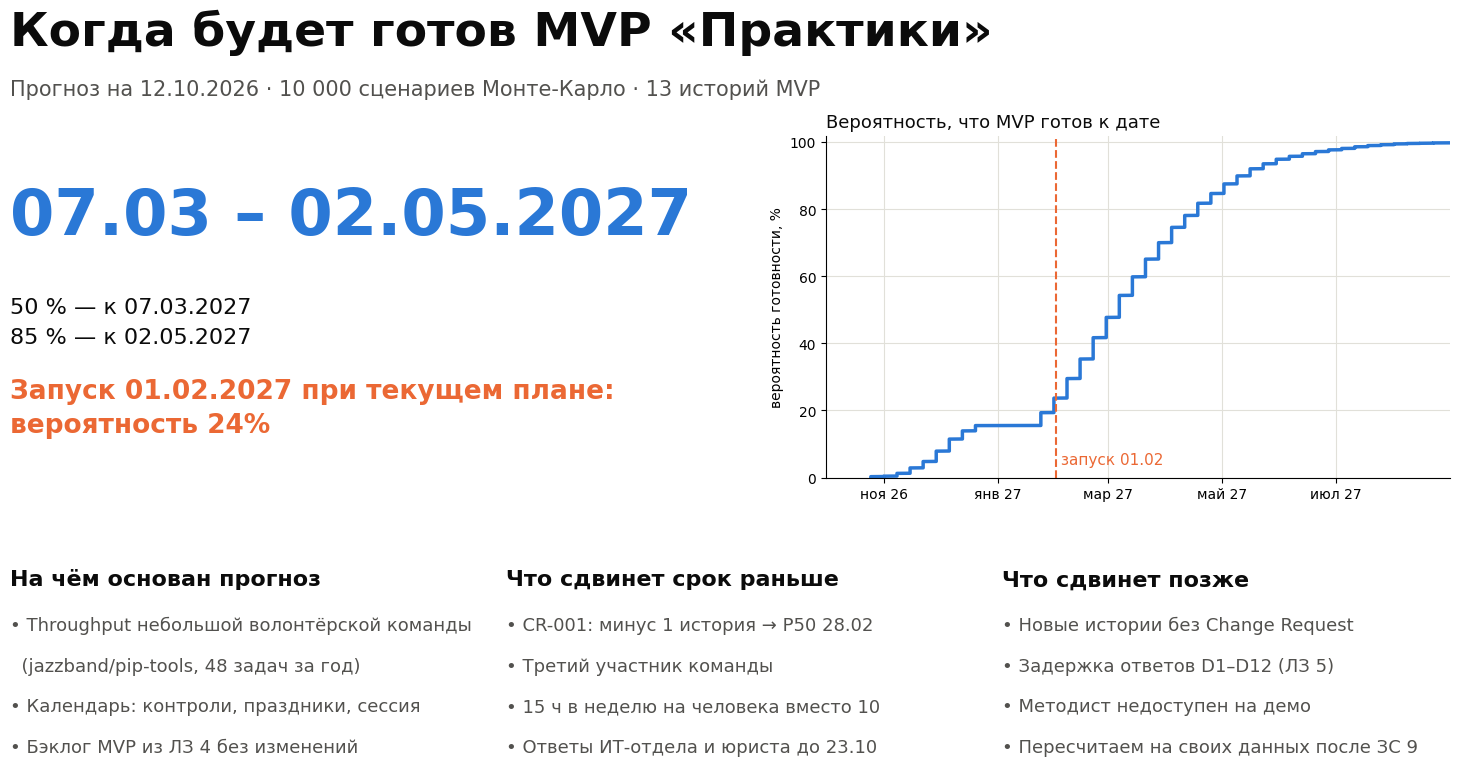

In [8]:
p_m4 = (mvp <= np.datetime64(DEADLINES["M4 · запуск 01.02.2027"])).mean()
cr = results[f"MVP после CR-001 ({N_MVP - 1})"]
fig = plt.figure(figsize=(16, 9), dpi=100)
fig.patch.set_facecolor("white")
fig.text(0.05, 0.9, "Когда будет готов MVP «Практики»", fontsize=34, fontweight="bold", color=INK)
fig.text(0.05, 0.845, f"Прогноз на 12.10.2026 · 10 000 сценариев Монте-Карло · {N_MVP} историй MVP", fontsize=15, color="#52514e")
fig.text(0.05, 0.69, f"{ps[50]:%d.%m} – {ps[85]:%d.%m.%Y}", fontsize=46, fontweight="bold", color=BLUE)
fig.text(0.05, 0.62, f"50 % — к {fmt(ps[50])}\n85 % — к {fmt(ps[85])}", fontsize=16, color=INK, va="top", linespacing=1.6)
fig.text(0.05, 0.47, f"Запуск 01.02.2027 при текущем плане:\nвероятность {p_m4:.0%}", fontsize=19, fontweight="bold",
         color=ORANGE, linespacing=1.4)

ax = fig.add_axes([0.56, 0.42, 0.39, 0.38])
xs = np.sort(mvp.astype("datetime64[D]").astype(date))
ax.plot(xs, np.arange(1, len(xs) + 1) / len(xs) * 100, color=BLUE, lw=2.5)
ax.axvline(DEADLINES["M4 · запуск 01.02.2027"], color=ORANGE, ls="--")
ax.text(DEADLINES["M4 · запуск 01.02.2027"], 4, " запуск 01.02", color=ORANGE, fontsize=11)
ax.set_ylabel("вероятность готовности, %")
ax.set_ylim(0, 102)
ax.grid(color="#e1e0d9")
MONTHS = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]
ax.xaxis.set_major_locator(matplotlib.dates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(
    lambda v, _: (lambda d: f"{MONTHS[d.month - 1]} {d:%y}")(matplotlib.dates.num2date(v))))
ax.set_xlim(date(2026, 10, 1), date(2027, 8, 31))
ax.set_title("Вероятность, что MVP готов к дате", loc="left", fontsize=13, color=INK)

cols = [
    ("На чём основан прогноз", [
        "Throughput небольшой волонтёрской команды",
        "(jazzband/pip-tools, 48 задач за год)",
        "Календарь: контроли, праздники, сессия",
        "Бэклог MVP из ЛЗ 4 без изменений"]),
    ("Что сдвинет срок раньше", [
        f"CR-001: минус 1 история → P50 {percentiles(cr)[50]:%d.%m}",
        "Третий участник команды",
        "15 ч в неделю на человека вместо 10",
        "Ответы ИТ-отдела и юриста до 23.10"]),
    ("Что сдвинет позже", [
        "Новые истории без Change Request",
        "Задержка ответов D1–D12 (ЛЗ 5)",
        "Методист недоступен на демо",
        "Пересчитаем на своих данных после ЗС 9"]),
]
for i, (title, items) in enumerate(cols):
    x = 0.05 + i * 0.31
    fig.text(x, 0.30, title, fontsize=16, fontweight="bold", color=INK)
    for j, t in enumerate(items):
        fig.text(x, 0.25 - j * 0.045, ("• " if not t.startswith("(") else "  ") + t, fontsize=13, color="#52514e")
fig.savefig(ROOT / "analytics" / "forecast-slide.png", dpi=100)
plt.show()

## Вывод

Сказать заказчику «MVP будет 18 декабря» нельзя: по симуляции вероятность этого около 14 %. Честная формулировка: **с вероятностью 50 % MVP будет готов к началу марта 2027, с вероятностью 85 % — к началу мая**. Запуск 1 февраля при текущем плане имеет шанс около четверти. Чтобы его повысить, нужны решения из ЛЗ 5: CR-001, 15 ч в неделю и третий участник. После двух спринтов пересчитываем на собственном throughput.